# 機械翻訳の自動評価と人手評価の相関（BLEU・chrF・BERTScore・COMET・品質推定）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_mt_eval.ipynb)

書籍 第2章（2-3 文章の品質推定、2-4 演習：品質推定、練習問題 3）と第4章（4-2-4 評価）に対応します。

練習問題 3 では、参照訳を使う評価と使わない評価（品質推定）の利点と問題点を考えました。このノートブックでは、両者を**同じ翻訳・同じ人手評価**で比べて、その違いを数字で確かめます。

1. **データの準備**：WMT22 の英日翻訳（13 システム、各 1,181 文）と、参照訳、人手評価のスコア
2. **参照訳を使う評価**：BLEU・chrF（表層の一致）、BERTScore（埋め込みの類似度）、COMET（人手評価で学習した評価モデル）
3. **参照訳を使わない評価**：COMET-QE（品質推定）
4. **人手評価との相関（メタ評価）**：文単位とシステム単位で、Pearson・Spearman・Kendall を比べる
5. **参照訳が 1 つしかないことの影響**：正しい言い換えが低く出る例と、参照訳を増やす実験

[第1章の品質推定の演習](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_qe.ipynb)で使った WMT21・WMT22 の品質推定のデータには参照訳が付いていないので、ここでは参照訳と人手評価の両方がある WMT22 の翻訳タスクのデータを使います。BLEU の定義と図 4.11（参照訳の数と BLEU）は[機械翻訳の自動評価 (BLEU) の演習](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_bleu_corpus.ipynb)で扱っています。

COMET などのモデルを動かすので、[ランタイム] → [ランタイムのタイプを変更] から [ハードウェア アクセラレータ] を `GPU`（T4 など）にしておいてください。検証の GPU では、全体の実行に 5 分ほどかかりました（T4 ではもう少しかかります）。

In [1]:
import torch

if torch.cuda.is_available():
    print("GPU が使えます")
else:
    print("警告: GPU が見つかりません（CPU で実行されます）。Colab の「ランタイム」→「ランタイムのタイプを変更」から GPU を選択してください。")

GPU が使えます


## 1. データの準備

[WMT22 の翻訳タスク](https://www.statmt.org/wmt22/translation-task.html) (General Machine Translation) では、参加したシステムの訳文を人手で評価しています。英日翻訳の人手評価は DA+SQM という方法で、評価者は原文と訳文を見て 0〜100 の点を付けます（参照訳は見ません）。ここでは、この人手評価を整理して公開している [RicardoRei/wmt-sqm-human-evaluation](https://huggingface.co/datasets/RicardoRei/wmt-sqm-human-evaluation) (Apache-2.0) から英日の部分を使います。各行に、原文 `src`、システムの訳文 `mt`、参照訳 `ref`、人手評価 `score`、システム名 `system` があります。

In [2]:
import pandas as pd

url = "https://huggingface.co/datasets/RicardoRei/wmt-sqm-human-evaluation/resolve/main/train.csv"
df = pd.read_csv(url)
df = df[df["lp"] == "en-ja"].reset_index(drop=True)
print("訳文の数:", len(df), " システム数:", df["system"].nunique(), " 原文の数（システムあたり）:", len(df) // df["system"].nunique())
print("1 文あたりの評価者数:", df["annotators"].unique())
print(df["domain"].value_counts().to_dict())
df[["src", "mt", "ref", "score", "system"]].head()

訳文の数: 15353  システム数: 13  原文の数（システムあたり）: 1181
1 文あたりの評価者数: [1]
{'news': 4043, 'social': 3783, 'ecommerce': 3770, 'conversation': 3757}


,src,mt,ref,score,system
0,I'm sorry that your order is running late.,ご注文が遅くなってしまったことをお詫び申し上げます。,お客様のご注文が遅れており、申し訳ございません。,90.5,KYB
1,I've looked into it and I can see that your ar...,調べてみると、お住まいの地域は、現在大量の注文を受けていることが分かります。,お調べしましたところ、お客様のお住まいの地域で現在注文が殺到しており、それでお客様の注文に配...,64.0,KYB
2,But just an update there is now a rider that h...,しかし、ちょうど更新は、レストランに到着を確認したライダーが今あります。,でもちょうど情報が更新され、配達員が今、ご注文がレストランに届いたことを確認しました。,81.5,KYB
3,If for any reason you are unsatisfied with you...,何らかの理由あなたが満たされていないであなたの購入、最初に連絡する前に負帰還を残す/中立フィ...,お客様が何らかの理由でお買い上げの商品に満足できない場合は、悪い、またはどちらでもないの評価...,64.0,KYB
4,You have 30 days to return the item from the d...,注文した日から30日で返品できます。,ご注文日から30日以内に返品していただけます。,80.0,KYB


13 のシステムが同じ 1,181 文を訳していて、すべての訳文に人手評価が 1 つずつ付いています。分野はニュース・SNS・EC サイト・会話の 4 つです。参照訳は 1 つの原文に 1 つだけです。

人手評価の分布と、システムごとの平均を見ておきます。システムの平均の差は数点しかなく、多くのシステムが接戦であることがわかります。

In [3]:
print(df["score"].describe().round(2))
df.groupby("system")["score"].mean().sort_values(ascending=False).round(2)

count    15353.00
mean        82.58
std         13.90
min          0.00
25%         78.67
50%         85.00
75%         91.00
max        100.00
Name: score, dtype: float64


,score
system,
Online-B,84.28
JDExploreAcademy,84.25
NT5,84.08
DLUT,83.94
LanguageX,83.63
NAIST-NICT-TIT,83.30
Online-Y,83.19
Online-W,82.96
Lan-Bridge,82.87


## 2. 参照訳を使う評価：BLEU・chrF

BLEU は単語 n-gram、chrF は文字 n-gram の一致を測ります（chrF は単語分割に依存しません）。日本語の BLEU は単語分割が必要なので、WMT22 と同じく `sacrebleu` の `ja-mecab`（MeCab と IPA 辞書）で分割します。

文単位の BLEU は、高次の n-gram が 1 つも一致しないと 0 になりやすいので、`effective_order=True` で一致がない次数を除いて計算します（[第4章の BLEU の演習](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_bleu_corpus.ipynb)の第 2 節を参照）。システム単位では、文単位の平均ではなく、本来の定義どおりコーパス全体で BLEU・chrF を計算します。

In [4]:
!pip install -q "sacrebleu[ja]" bert-score

In [5]:
from sacrebleu.metrics import BLEU, CHRF

bleu = BLEU(tokenize="ja-mecab", effective_order=True)
chrf = CHRF()
df["bleu"] = [bleu.sentence_score(h, [r]).score for h, r in zip(df["mt"], df["ref"])]
df["chrf"] = [chrf.sentence_score(h, [r]).score for h, r in zip(df["mt"], df["ref"])]
print(bleu.get_signature())
print(chrf.get_signature())
df[["bleu", "chrf"]].describe().round(2)

nrefs:1|case:mixed|eff:yes|tok:ja-mecab-0.996-IPA|smooth:exp|version:2.6.0
nrefs:1|case:mixed|eff:yes|nc:6|nw:0|space:no|version:2.6.0


,bleu,chrf
count,15353.00,15353.00
mean,23.01,33.35
std,17.27,17.75
min,0.00,0.00
25%,9.60,20.04
50%,18.58,31.03
75%,31.98,43.57
max,100.00,100.00


## 3. 参照訳を使う評価：BERTScore

BERTScore は、訳文と参照訳の各トークンの文脈付き埋め込みを比べ、最も近いトークン同士のコサイン類似度から適合率・再現率・F1 を計算します。表記が違っても意味の近い語には部分点が入ります。`lang="ja"` では多言語 BERT (`bert-base-multilingual-cased`) が使われます。ここでは F1 を使います。

In [6]:
from bert_score import score as bert_score

_, _, F = bert_score(df["mt"].tolist(), df["ref"].tolist(), lang="ja", batch_size=128, verbose=False)
df["bertscore"] = F.numpy()
df["bertscore"].describe().round(4)

,bertscore
count,15353.0000
mean,0.8314
std,0.0628
min,0.5834
25%,0.7882
50%,0.8320
75%,0.8751
max,1.0000


## 4. COMET（参照訳あり）と COMET-QE（参照訳なし）

[COMET](https://github.com/Unbabel/COMET) は、原文・訳文・参照訳を XLM-R に入力して、人手評価のスコアを予測するように学習した評価モデルです。ここでは参照訳を使う `Unbabel/wmt22-comet-da` と、参照訳を使わない品質推定モデル `Unbabel/wmt20-comet-qe-da`（[第1章の品質推定の演習](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_qe.ipynb)で使ったもの）を比べます。どちらも Apache-2.0 で公開されています。

`wmt22-comet-da` は WMT17〜20 の人手評価で、`wmt20-comet-qe-da` は WMT17〜19 の人手評価で学習されているので、ここで使う WMT22 のデータは学習に含まれていません。なお、より新しい品質推定モデル `Unbabel/wmt22-cometkiwi-da` は、利用規約への同意（Hugging Face のゲート）が必要で非商用ライセンスなので、ここでは使いません。

第1章と同じく、COMET は [uv](https://docs.astral.sh/uv/) で作った別の仮想環境に入れて、`comet-score` コマンドで動かします。数分かかります。

In [7]:
!pip install -q uv
!uv venv -q --clear -p 3.12 /content/comet-env
!uv pip install -q -p /content/comet-env unbabel-comet "setuptools<70"

同じ原文に対して複数のシステムが同じ訳文を出していることがあるので、重複を除いた組だけをファイルに書き出して評価し、結果を元の表に戻します。参照訳ありのモデルには `-r` で参照訳を渡し、品質推定のモデルには渡しません。CPU ランタイムで実行する場合は、`comet-score` に `--gpus 0` を付けてください。

In [8]:
uniq = df[["src", "mt", "ref"]].drop_duplicates().reset_index(drop=True)
print("評価する組の数:", len(uniq))
for col in ["src", "mt", "ref"]:
    # 改行が入っていると行がずれるので空白に置き換える
    open(f"uniq.{col}", "w", encoding="utf-8").write("\n".join(uniq[col].str.replace("\n", " ")) + "\n")

!/content/comet-env/bin/comet-score -s uniq.src -t uniq.mt -r uniq.ref --model Unbabel/wmt22-comet-da --batch_size 64 --quiet > comet_da.txt 2> comet_da.log
!/content/comet-env/bin/comet-score -s uniq.src -t uniq.mt --model Unbabel/wmt20-comet-qe-da --batch_size 64 --quiet > comet_qe.txt 2> comet_qe.log
!head -n 2 comet_da.txt comet_qe.txt

評価する組の数: 13013
==> comet_da.txt <==
uniq.mt	Segment 0	score: 0.9243
uniq.mt	Segment 1	score: 0.8149

==> comet_qe.txt <==
uniq.mt	Segment 0	score: 0.5718
uniq.mt	Segment 1	score: 0.0486


In [9]:
def read_comet(path):
    with open(path, encoding="utf-8") as f:
        scores = [float(l.split("score:")[-1]) for l in f if "Segment" in l]
    assert len(scores) == len(uniq), f"件数不一致: {len(scores)} != {len(uniq)}"
    return scores

uniq["comet"] = read_comet("comet_da.txt")
uniq["comet_qe"] = read_comet("comet_qe.txt")
df = df.merge(uniq, on=["src", "mt", "ref"], how="left")
df[["comet", "comet_qe"]].describe().round(4)

,comet,comet_qe
count,15353.0000,15353.0000
mean,0.8715,0.2504
std,0.0949,0.3470
min,0.3093,-1.3428
25%,0.8379,0.0505
50%,0.9009,0.3308
75%,0.9365,0.5078
max,0.9922,0.9380


## 5. 人手評価との相関（メタ評価）

自動評価のスコアと人手評価のスコアの相関を測ります（評価尺度の評価なので、メタ評価と呼ばれます）。相関係数の意味は[第1章の品質推定の演習](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_qe.ipynb)の「評価尺度」の節と同じです。

- **文単位**：15,353 個の訳文それぞれについて、自動評価と人手評価の相関を測ります。「この訳文は良いか」を見分けられるかを表します。
- **システム単位**：13 システムそれぞれの平均（BLEU・chrF はコーパス単位のスコア）と、人手評価の平均の相関を測ります。「どのシステムが良いか」を順位づけられるかを表します。WMT の評価尺度の共通タスクでも、この 2 つを分けて報告しています。

In [10]:
from scipy.stats import pearsonr, spearmanr, kendalltau

metrics = [
    ("BLEU", "bleu", "参照訳あり"),
    ("chrF", "chrf", "参照訳あり"),
    ("BERTScore", "bertscore", "参照訳あり"),
    ("COMET", "comet", "参照訳あり"),
    ("COMET-QE", "comet_qe", "参照訳なし"),
]

def correlations(x, y):
    return {"Pearson": pearsonr(x, y)[0], "Spearman": spearmanr(x, y)[0], "Kendall": kendalltau(x, y)[0]}

seg = pd.DataFrame([{"指標": name, "参照訳": kind, **correlations(df[col], df["score"])} for name, col, kind in metrics])
print("文単位の相関（15,353 文）")
seg.round(4)

文単位の相関（15,353 文）


,指標,参照訳,Pearson,Spearman,Kendall
0,BLEU,参照訳あり,0.2051,0.1982,0.1349
1,chrF,参照訳あり,0.2248,0.2077,0.1423
2,BERTScore,参照訳あり,0.2749,0.2583,0.1769
3,COMET,参照訳あり,0.3640,0.3452,0.2389
4,COMET-QE,参照訳なし,0.3153,0.2794,0.1906


In [11]:
import numpy as np

# システム単位の BLEU・chrF はコーパス全体で計算する。文ごとの一致数などの統計量を先に求めておくと、
# 文の集合を変えたときのコーパス単位のスコアを、統計量の足し算だけで計算できる（下のブートストラップ法で使う）
bleu_corpus, chrf_corpus = BLEU(tokenize="ja-mecab"), CHRF()
stats = {name: np.array(m._extract_corpus_statistics(df["mt"].tolist(), [df["ref"].tolist()]))
         for name, m in [("bleu", bleu_corpus), ("chrf", chrf_corpus)]}

def system_scores(rows):
    sub = df.iloc[rows]
    out = sub.groupby("system")[["score", "bertscore", "comet", "comet_qe"]].mean().rename(columns={"score": "human"})
    for name, m in [("bleu", bleu_corpus), ("chrf", chrf_corpus)]:
        out[name] = [m._compute_score_from_stats(stats[name][rows[sub["system"].to_numpy() == system]].sum(0).tolist()).score
                     for system in out.index]
    return out[["human", "bleu", "chrf", "bertscore", "comet", "comet_qe"]]

sys_df = system_scores(np.arange(len(df))).sort_values("human", ascending=False)
# 足し算で求めた値が corpus_score と一致することを確かめる
x = df[df["system"] == sys_df.index[0]]
assert abs(sys_df["bleu"].iloc[0] - bleu_corpus.corpus_score(x["mt"].tolist(), [x["ref"].tolist()]).score) < 1e-6

sys_corr = pd.DataFrame([{"指標": name, "参照訳": kind, **correlations(sys_df[col], sys_df["human"])} for name, col, kind in metrics])
display(sys_df.round(4))
print("システム単位の相関（13 システム）")
sys_corr.round(4)

,human,bleu,chrf,bertscore,comet,comet_qe
system,,,,,,
Online-B,84.2780,26.0450,35.0116,0.8372,0.8855,0.2882
JDExploreAcademy,84.2509,26.6674,35.9086,0.8409,0.8960,0.3314
NT5,84.0777,27.4773,36.6410,0.8425,0.8924,0.3155
DLUT,83.9394,27.2046,35.9742,0.8390,0.8851,0.2972
LanguageX,83.6317,26.9212,35.6189,0.8410,0.8860,0.2814
NAIST-NICT-TIT,83.2971,24.4670,33.5223,0.8309,0.8708,0.2517
Online-Y,83.1936,24.7844,33.8440,0.8331,0.8752,0.2601
Online-W,82.9633,26.7050,34.6999,0.8357,0.8860,0.2869
Lan-Bridge,82.8718,24.3640,33.6322,0.8332,0.8749,0.2631


システム単位の相関（13 システム）


,指標,参照訳,Pearson,Spearman,Kendall
0,BLEU,参照訳あり,0.9189,0.7473,0.5641
1,chrF,参照訳あり,0.9288,0.8297,0.6410
2,BERTScore,参照訳あり,0.9264,0.8571,0.6410
3,COMET,参照訳あり,0.9124,0.8297,0.6923
4,COMET-QE,参照訳なし,0.8910,0.8736,0.7179


システム単位の散布図も描いてみます。横軸が人手評価の平均、縦軸が各指標です。

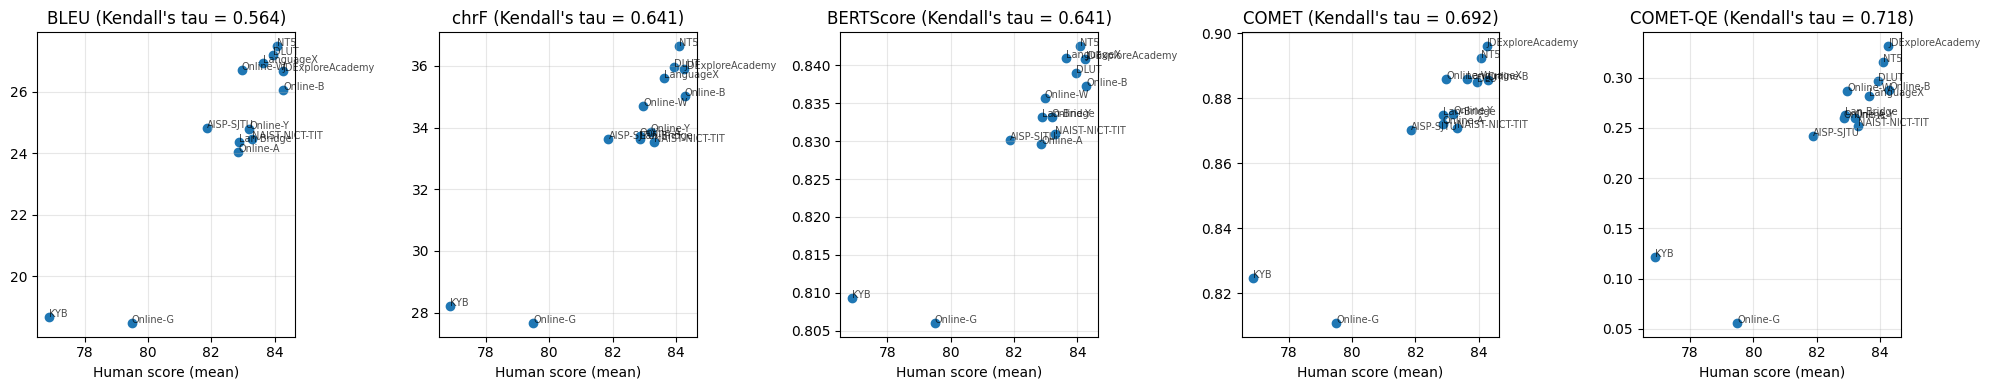

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(metrics), figsize=(20, 4))
for ax, (name, col, _) in zip(axes, metrics):
    ax.scatter(sys_df["human"], sys_df[col])
    for system, row in sys_df.iterrows():
        ax.annotate(system, (row["human"], row[col]), fontsize=7, alpha=0.7)
    tau = kendalltau(sys_df[col], sys_df["human"])[0]
    ax.set_title(f"{name} (Kendall's tau = {tau:.3f})")
    ax.set_xlabel("Human score (mean)")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### システム単位の相関はどれくらい当てになるか

13 システムしかないので、システム単位の相関は、どの原文で評価したかによって大きく揺れます。原文を復元抽出して評価をやり直すブートストラップ法で、Kendall's tau の 95% 信頼区間を求めてみます（BLEU・chrF も、抽出した文でコーパス単位のスコアを計算し直します）。1,000 回繰り返します。

In [13]:
rng = np.random.default_rng(0)
seg_ids = df.groupby(["src", "ref"]).ngroup().to_numpy()  # 同じ原文に対する 13 システムの訳文に同じ番号を付ける
n_seg = seg_ids.max() + 1
by_seg = [np.where(seg_ids == i)[0] for i in range(n_seg)]

boot = {name: [] for name, _, _ in metrics}
for _ in range(1000):
    rows = np.concatenate([by_seg[i] for i in rng.integers(0, n_seg, n_seg)])
    s = system_scores(rows)
    for name, col, _ in metrics:
        boot[name].append(kendalltau(s[col], s["human"])[0])

pd.DataFrame([{"指標": name, "Kendall": kendalltau(sys_df[col], sys_df["human"])[0],
               "95% 区間（下）": np.percentile(boot[name], 2.5), "95% 区間（上）": np.percentile(boot[name], 97.5)}
              for name, col, _ in metrics]).round(3)

,指標,Kendall,95% 区間（下）,95% 区間（上）
0,BLEU,0.564,0.410,0.718
1,chrF,0.641,0.487,0.795
2,BERTScore,0.641,0.512,0.795
3,COMET,0.692,0.487,0.821
4,COMET-QE,0.718,0.538,0.821


**文単位**では、参照訳を使う COMET の相関が最も高く (Kendall 0.239)、次が参照訳を使わない COMET-QE (0.191) で、BERTScore (0.177)、chrF (0.142)、BLEU (0.135) と続きます。

- 表層の一致を見る BLEU・chrF より、埋め込みを使う BERTScore が、さらに人手評価で学習した COMET が高い相関になります。
- 参照訳を見ない COMET-QE が、参照訳を使う BLEU・chrF・BERTScore を上回っています。参照訳があれば評価が良くなるとは限らず、「どう使うか」が大事です。一方、同じ COMET 同士では参照訳を使うほうが高く、参照訳には品質を判断する手がかりがあることもわかります。
- どの指標も相関の値は 0.4 に届きません。人手評価も 1 文につき 1 人の評価者が付けた点数なので揺れが大きく、文単位で人手評価と完全に一致することは期待できません。

**システム単位**では、Pearson はどの指標も 0.89〜0.93 と高くなります。散布図を見ると、人手評価が特に低い Online-G と KYB の 2 つが離れていて、この 2 つを下位に置けば Pearson は高くなります。上位の接戦のシステムを正しく並べられるかは順位相関に表れ、Kendall は BLEU の 0.564 から COMET-QE の 0.718 まで差があります。例えば Online-W は、人手評価では 13 システム中 8 位ですが、BLEU は 4 位です。

ただし、ブートストラップ法の 95% 区間 (BLEU 0.410〜0.718、COMET-QE 0.538〜0.821) は大きく重なっています。13 システム程度では、システム単位の相関の差から「どの指標が良いか」を言い切ることはできません。WMT の評価尺度の共通タスクでは、多くの言語対とシステムで結果を集めて判断しています。

## 6. 参照訳が 1 つしかないことの影響

参照訳を使う評価は、訳文が参照訳に近いほど高く評価します。しかし、正しい翻訳は 1 つではありません。参照訳と違う言い回しで正しく訳すと、表層の一致を見る BLEU・chrF は低くなります。

人手評価が 95 点以上なのに、文単位の BLEU が 10 未満の訳文を探してみます。

In [14]:
high = df[df["score"] >= 95]
low_bleu = high[high["bleu"] < 10]
print(f"人手評価 95 点以上: {len(high)} 文、そのうち BLEU < 10: {len(low_bleu)} 文 ({len(low_bleu) / len(high):.1%})")
print("BLEU < 10 の訳文の各指標の平均:")
print(low_bleu[["bleu", "chrf", "bertscore", "comet", "comet_qe"]].mean().round(3).to_dict())
print("人手評価 95 点以上の訳文全体の各指標の平均:")
print(high[["bleu", "chrf", "bertscore", "comet", "comet_qe"]].mean().round(3).to_dict())

人手評価 95 点以上: 1977 文、そのうち BLEU < 10: 405 文 (20.5%)
BLEU < 10 の訳文の各指標の平均:
{'bleu': 6.515, 'chrf': 16.223, 'bertscore': 0.772, 'comet': 0.833, 'comet_qe': 0.242}
人手評価 95 点以上の訳文全体の各指標の平均:
{'bleu': 27.204, 'chrf': 38.185, 'bertscore': 0.85, 'comet': 0.904, 'comet_qe': 0.349}


In [15]:
pd.set_option("display.max_colwidth", 80)
cols = ["src", "ref", "mt", "score", "bleu", "chrf", "comet", "comet_qe"]
examples = low_bleu[low_bleu["ref"].str.len() >= 20].drop_duplicates("src").sort_values("bleu").head(6)
examples[cols].round(3)

,src,ref,mt,score,bleu,chrf,comet,comet_qe
787,Comes in a Haryali London Gift Designer Box,ハリヤリロンドンのデザイナー化粧箱入り。,Haryaliロンドンギフトデザイナーボックスに入っています,99.000,0.000,20.858,0.824,-0.312
8089,I understand that you have already tried turning it off and back on with no ...,いったん電源を切ってから入れ直してみたけれどうまくいかなかったということでよろしいでしょうか？,私はあなたがすでにそれをオフにして、成功せずに再びオンにしようとしていたことを理解しています、正しいですか?,99.000,1.576,9.341,0.787,0.338
927,"""This is one of those times when we aren't Democrats or Republicans.""",「民主党か共和党かといっている場合ではない。」,これは、私達が民主党員達でも共和党員達でもない、それらの時代の内の1つです。,95.000,1.997,11.774,0.697,0.193
592,"We will refund delivery costs if the goods are faulty, but for all other ret...",商品に不備がある場合には返送費用を払い戻しますが、その他の返品につきましては、適応外です。,私たちは払い戻し配信コスト場合は商品が欠陥、しかし、他のすべてのリターン、これは適用されません。,95.000,2.375,11.804,0.617,-0.378
1039,Will she also work late to get it done for the court deadline?,裁判の期日に間に合うように、あなたも残業する？,彼女はまた、裁判所の期限のためにそれを終わらせるために遅く働くでしょうか?,96.000,2.443,7.804,0.805,-0.317
6909,"In some communities, the church provides a safe place for some persecuted so...",あるコミュニティで、虐げられてる社会的グループにとって教会が安らぎの場になるってことあるよな。,地域によっては、教会は迫害されている社会集団に安全な場所を提供しています。,95.333,2.462,8.948,0.881,0.596


人手評価が 95 点以上の訳文 1,977 文のうち、2 割（405 文）は文単位の BLEU が 10 未満です。これらの訳文では、BLEU・chrF の平均は 95 点以上の訳文全体の平均の半分以下ですが、COMET は 0.904 から 0.833 に下がるだけです。

上の例を見ると、次の 2 種類が混ざっています。

- **参照訳と違う言い回しの正しい訳**：例えば教会の文 (6909) は、参照訳が「…安らぎの場になるってことあるよな。」というくだけた話し言葉で、訳文は「…安全な場所を提供しています。」という書き言葉です。意味は合っていても、共通の n-gram がほとんどないので BLEU は 2.5 になります。電源の文 (8089) も、参照訳の「…ということでよろしいでしょうか？」と訳文の「…を理解しています、正しいですか?」で言い回しが違います。COMET はどちらも 0.78 以上です。
- **人手評価のほうが甘い訳**：返品の文 (592) の訳文「私たちは払い戻し配信コスト場合は商品が欠陥、…」は日本語として崩れていますが、人手評価は 95 点です。人手評価も 1 人の評価者の点数なので、このような揺れがあります。BLEU・chrF が低いのはこの場合は正しく、COMET も 0.617 と低めです。

参照訳を使う評価は、参照訳と比べた根拠を確かめやすい反面、参照訳が 1 つだと正しい言い換えを低く評価します。また、COMET-QE は参照訳を見ないので、デザイナーボックスの文 (787) のように正しい訳を低く (-0.312) 評価することもあります。

### 参照訳を増やすと何が変わるか

参照訳の数を増やすと、正しい言い換えが参照訳のどれかと一致しやすくなります（書籍 図 4.11）。このデータには参照訳が 1 つしかないので、代わりに**同じ原文に対する他のシステムの訳文のうち、人手評価が 95 点以上のもの**を、追加の参照訳として使ってみます。評価する訳文そのものと同じ文字列は追加の参照訳から除きます。

これは人手評価を使って参照訳を選んでいるので、実際の評価に使える方法ではありません。「人が正しいと認めた別の訳が参照訳にあったら、表層の一致を見る指標はどれくらい良くなるか」を確かめるための実験です。

In [16]:
good = df[df["score"] >= 95].groupby("src")[["system", "mt"]].apply(lambda x: list(zip(x["system"], x["mt"]))).to_dict()

def extra_refs(row):
    return list(dict.fromkeys(mt for system, mt in good.get(row["src"], [])
                              if system != row["system"] and mt != row["mt"]))

df["extra_refs"] = df.apply(extra_refs, axis=1)
print("追加の参照訳の数（平均）:", round(df["extra_refs"].str.len().mean(), 2),
      " 追加の参照訳が 1 つ以上ある訳文の割合:", f"{(df['extra_refs'].str.len() > 0).mean():.1%}")

df["bleu_multi"] = [bleu.sentence_score(h, [r] + e).score for h, r, e in zip(df["mt"], df["ref"], df["extra_refs"])]
df["chrf_multi"] = [chrf.sentence_score(h, [r] + e).score for h, r, e in zip(df["mt"], df["ref"], df["extra_refs"])]

pd.DataFrame([{"指標": name, **correlations(df[col], df["score"])} for name, col in [
    ("BLEU（参照訳 1 つ）", "bleu"), ("BLEU（参照訳を追加）", "bleu_multi"),
    ("chrF（参照訳 1 つ）", "chrf"), ("chrF（参照訳を追加）", "chrf_multi"),
    ("COMET（参照訳 1 つ）", "comet"), ("COMET-QE（参照訳なし）", "comet_qe"),
]]).round(4)

追加の参照訳の数（平均）: 1.3  追加の参照訳が 1 つ以上ある訳文の割合: 59.5%


,指標,Pearson,Spearman,Kendall
0,BLEU（参照訳 1 つ）,0.2051,0.1982,0.1349
1,BLEU（参照訳を追加）,0.2531,0.2864,0.1957
2,chrF（参照訳 1 つ）,0.2248,0.2077,0.1423
3,chrF（参照訳を追加）,0.2626,0.2862,0.1957
4,COMET（参照訳 1 つ）,0.3640,0.3452,0.2389
5,COMET-QE（参照訳なし）,0.3153,0.2794,0.1906


追加の参照訳は 1 文あたり平均 1.3 個で、6 割の訳文に 1 つ以上付きました。参照訳を増やすと、文単位の Kendall は BLEU が 0.135 から 0.196 に、chrF が 0.142 から 0.196 に上がり、参照訳なしの COMET-QE (0.191) と同じくらいになりました。参照訳が 1 つしかないことが、表層の一致を見る指標の相関を下げている原因の 1 つであることがわかります。

それでも、参照訳 1 つの COMET (0.239) には届きません。COMET は、学習によって言い換えや語の重要さをある程度考慮できるので、少ない参照訳でも人手評価に近い判断ができます。

## 7. まとめ

- 同じ WMT22 の英日翻訳と人手評価で比べると、文単位の相関は COMET（参照訳あり）> COMET-QE（参照訳なし）> BERTScore > chrF > BLEU の順でした。
- 参照訳を使う評価は、参照訳との違いという根拠を示せますが、参照訳が 1 つだと正しい言い換えを低く評価します。人が正しいと認めた別の訳を参照訳に足すと、BLEU・chrF の相関は上がりました。
- 参照訳を使わない品質推定は、参照訳がなくても使え、ここでは BLEU・chrF・BERTScore より人手評価に近い結果でした。ただし、英日は COMET-QE の学習データに含まれていないので、使う言語・分野で人手評価とどの程度一致するかを確かめる必要があります（練習問題 3）。
- システム単位の相関は、少数の外れたシステムで Pearson が高くなりやすく、13 システム程度では指標の差を言い切れません。人手評価自体も揺れるので、自動評価の数値は信頼区間と合わせて読みます。

### 考えてみよう

- 文単位の BLEU と chrF はどちらも表層の一致を見る指標です。日本語で chrF のほうが相関が高くなりやすいのはなぜでしょうか。BLEU の単語分割を `ja-mecab` 以外（例えば `char`）にすると、相関はどう変わるでしょうか。
- 第 6 節の例で、COMET-QE は参照訳を見ずに高い点を付けています。逆に、参照訳がないために COMET-QE が見逃しそうな誤りにはどのようなものがあるでしょうか（[第1章の品質推定の演習](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_qe.ipynb)の「過大評価された例」も参照）。
- 分野 (`domain`) ごとに相関を計算すると、指標の順位は変わるでしょうか。

### NLP クックブックの関連レシピ

- [自動評価指標と人手評価の相関を調べる（14. 評価指標と統計的検定）](https://github.com/mamorlis/nlpcookbook/blob/main/notebooks/14_evaluation/metric_correlation.ipynb)
- [BERTScore で意味的な近さを評価する（14. 評価指標と統計的検定）](https://github.com/mamorlis/nlpcookbook/blob/main/notebooks/14_evaluation/bertscore.ipynb)
- [chrF と TER で翻訳を評価する（27. 機械翻訳）](https://github.com/mamorlis/nlpcookbook/blob/main/notebooks/27_machine_translation/chrf_ter.ipynb)
- [COMET で翻訳の品質を評価する（27. 機械翻訳）](https://github.com/mamorlis/nlpcookbook/blob/main/notebooks/27_machine_translation/comet.ipynb)